# 03 — Modelos, baselines y búsqueda de hiperparámetros
## Proyecto final de Machine Learning — Grupo 11 · Lending Club

**Objetivo:** comparar de forma justa tres familias de modelos contra un baseline honesto, ajustar hiperparámetros sin mirar el test
y decidir con evidencia (a) qué modelo se lleva a la evaluación final y (b) cuánto aportan `grade`/`sub_grade`/`int_rate` (zona gris).

**Reglas de este notebook**
- **El test no se carga ni se toca.** Solo se usan `train` (2012–2014) y `valid` (2015). La evaluación final se hace una sola vez, después.
- Los hiperparámetros se eligen con **validación cruzada temporal dentro de train** (cada fold entrena con años anteriores y valida en el siguiente).
- La comparación entre modelos se hace en **valid**, con métricas independientes del umbral (AUC-PR, KS) y una métrica operativa (recall a precisión fija).
- Todo el preprocesamiento vive dentro del `Pipeline`, así se ajusta solo con los datos de entrenamiento de cada fold.

**Familias comparadas:** regresión logística (lineal, interpretable), random forest (bagging de árboles) y gradient boosting (`HistGradientBoostingClassifier`).


In [4]:
import os
import sys
import json
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from src import config, data, evaluate, features

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
SEED = config.SEED
np.random.seed(SEED)

# QUICK_RUN=1 reduce muestras e iteraciones para depurar rápido; sin esa variable corre la versión completa.
QUICK = os.environ.get("QUICK_RUN") == "1"
SEARCH_SAMPLE = 20_000 if QUICK else 150_000   # filas de train usadas SOLO para la búsqueda de hiperparámetros
N_ITER_RF = 2 if QUICK else 6
N_ITER_HGB = 3 if QUICK else 10
FINAL_TRAIN_SAMPLE = None                      # p. ej. 250_000 si el entrenamiento final es muy lento
MIN_PRECISION = 0.40                           # para recall a precisión fija

config.OUTPUTS.mkdir(parents=True, exist_ok=True)
config.FIGURES.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(config.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")


## 1. Carga de los splits (sin test)

In [5]:
train, valid = data.load_splits(("train", "valid"))
print(f"Train: {len(train):,} filas ({train['issue_year'].min()}-{train['issue_year'].max()}) | tasa de default: {train['target'].mean():.3f}")
print(f"Valid: {len(valid):,} filas ({valid['issue_year'].min()}-{valid['issue_year'].max()}) | tasa de default: {valid['target'].mean():.3f}")


def get_xy(df, grey=False):
    num, cat = features.get_feature_lists(grey)
    return df[num + cat], df["target"].values


def make_pipeline(model, grey=False, scale=True):
    prep = features.build_preprocessor(include_grey_zone=grey, scale=scale)
    return Pipeline([("prep", prep), ("clf", model)])


Train: 411,274 filas (2012-2014) | tasa de default: 0.172
Valid: 375,546 filas (2015-2015) | tasa de default: 0.202


## 2. Baselines

Dos referencias antes de ajustar nada:
1. **Sin habilidad (prior):** predice siempre la tasa de default. Su AUC-PR es igual a la tasa de default; es el piso absoluto.
2. **Regresión logística sin ajustar (C = 1):** el baseline propuesto en `proposal.md`, ahora re-ejecutado con el split definitivo.


In [6]:
X_tr, y_tr = get_xy(train)
X_va, y_va = get_xy(valid)

resultados = {}   # (modelo, variante) -> métricas en valid
scores = {}       # (modelo, variante) -> probabilidades en valid

dummy = DummyClassifier(strategy="prior").fit(np.zeros((len(y_tr), 1)), y_tr)
p_dummy = dummy.predict_proba(np.zeros((len(y_va), 1)))[:, 1]
resultados[("Sin habilidad (prior)", "sin zona gris")] = evaluate.evaluate_scores(y_va, p_dummy, MIN_PRECISION)
scores[("Sin habilidad (prior)", "sin zona gris")] = p_dummy

base_lr = make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED), scale=True)
base_lr.fit(X_tr, y_tr)
p_base = base_lr.predict_proba(X_va)[:, 1]
resultados[("Regresión logística (baseline, C=1)", "sin zona gris")] = evaluate.evaluate_scores(y_va, p_base, MIN_PRECISION)
scores[("Regresión logística (baseline, C=1)", "sin zona gris")] = p_base

pd.DataFrame(resultados).T.round(4)


,,pr_auc,roc_auc,ks,recall@p40,umbral@p40,lift_top10,brier,tasa_default
Sin habilidad (prior),sin zona gris,0.2019,0.5000,0.0000,0.0000,NaN,1.0000,0.1620,0.2019
"Regresión logística (baseline, C=1)",sin zona gris,0.3928,0.7131,0.3074,0.4346,0.6018,2.4196,0.2178,0.2019


**Lectura del baseline:** (completar) comparar el AUC-PR del baseline contra la tasa de default de valid, y comentar cuánto mejora sobre «sin habilidad».
Este número reemplaza al de la entrega previa (AUC-PR 0.273), que usó otro split y no es comparable.


## 3. Búsqueda de hiperparámetros (validación cruzada temporal dentro de train)

- Se usa una **submuestra aleatoria de train** (`SEARCH_SAMPLE`) solo para acelerar la búsqueda; el modelo final se entrena con todo train.
- Los folds son **temporales**: para cada año de train (menos el primero) se entrena con los años anteriores y se valida en ese año. Así la búsqueda respeta el orden del tiempo igual que la evaluación final.
- Métrica de la búsqueda: AUC-PR (`average_precision`).
- Se ajustan los hiperparámetros solo con las variables **sin zona gris**; el experimento con zona gris reutiliza esos mismos hiperparámetros (simplificación documentada).


In [7]:
MODELS = {
    "Regresión logística": dict(
        model=LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED), scale=True),
    "Random forest": dict(
        model=RandomForestClassifier(n_jobs=-1, class_weight="balanced_subsample", random_state=SEED), scale=False),
    "Gradient boosting": dict(
        model=HistGradientBoostingClassifier(random_state=SEED), scale=False),
}

SPACES = {
    "Regresión logística": ({"C": [0.001, 0.01, 0.1, 1, 10]}, None),   # None = búsqueda en malla completa
    "Random forest": ({
        "n_estimators": [100, 200], "max_depth": [8, 10, 14],
        "min_samples_leaf": [50, 100, 200], "max_features": ["sqrt", 0.4],
    }, N_ITER_RF),
    "Gradient boosting": ({
        "learning_rate": [0.03, 0.05, 0.1], "max_iter": [150, 300], "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [50, 200], "l2_regularization": [0.0, 1.0],
    }, N_ITER_HGB),
}


def temporal_folds(df):
    """Folds expansivos: entrena con años < y, valida en el año y."""
    years = sorted(df["issue_year"].unique())
    idx = np.arange(len(df))
    folds = []
    for y in years[1:]:
        tr = idx[(df["issue_year"] < y).values]
        va = idx[(df["issue_year"] == y).values]
        if len(tr) and len(va):
            folds.append((tr, va))
    return folds


search_df = train.sample(min(SEARCH_SAMPLE, len(train)), random_state=SEED).reset_index(drop=True)
folds = temporal_folds(search_df)
X_s, y_s = get_xy(search_df)
print(f"Muestra de búsqueda: {len(search_df):,} filas | folds temporales: {len(folds)}")
for i, (tr, va) in enumerate(folds, 1):
    print(f"  fold {i}: train={len(tr):,} (años < {search_df.loc[va, 'issue_year'].iloc[0]}) | valid={len(va):,}")


Muestra de búsqueda: 150,000 filas | folds temporales: 2
  fold 1: train=19,547 (años < 2013) | valid=49,071
  fold 2: train=68,618 (años < 2014) | valid=81,382


In [8]:
def tune(name):
    cfg = MODELS[name]
    space, n_iter = SPACES[name]
    pipe = make_pipeline(cfg["model"], grey=False, scale=cfg["scale"])
    grid = {f"clf__{k}": v for k, v in space.items()}
    if n_iter is None:
        search = GridSearchCV(pipe, grid, scoring="average_precision", cv=folds, n_jobs=1, refit=False)
    else:
        search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="average_precision", cv=folds,
                                    random_state=SEED, n_jobs=1, refit=False)
    search.fit(X_s, y_s)
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    best = {k.replace("clf__", ""): v for k, v in res.iloc[0]["params"].items()}
    return best, res


best_params, cv_tables = {}, {}
for name in MODELS:
    best_params[name], cv_tables[name] = tune(name)
    print(f"{name}: mejor AUC-PR CV = {cv_tables[name].iloc[0]['mean_test_score']:.4f}  |  {best_params[name]}")


Regresión logística: mejor AUC-PR CV = 0.3030  |  {'C': 0.001}
Random forest: mejor AUC-PR CV = 0.3014  |  {'n_estimators': 200, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': 10}
Gradient boosting: mejor AUC-PR CV = 0.3006  |  {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 150, 'learning_rate': 0.03, 'l2_regularization': 0.0}


In [9]:
for name, res in cv_tables.items():
    print(f"\n=== {name}: 5 mejores configuraciones ===")
    display(res[["params", "mean_test_score", "std_test_score"]].head(5).round(4))



=== Regresión logística: 5 mejores configuraciones ===


,params,mean_test_score,std_test_score
0,{'clf__C': 0.001},0.3030,0.0357
1,{'clf__C': 0.01},0.3026,0.0355
2,{'clf__C': 0.1},0.3024,0.0355
3,{'clf__C': 1},0.3023,0.0356
4,{'clf__C': 10},0.3023,0.0356



=== Random forest: 5 mejores configuraciones ===


,params,mean_test_score,std_test_score
1,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.3014,0.0355
2,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.3005,0.0364
0,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.2994,0.0360
5,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.2993,0.0352
4,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.2990,0.0364



=== Gradient boosting: 5 mejores configuraciones ===


,params,mean_test_score,std_test_score
3,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.3006,0.0357
9,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.2998,0.0368
8,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.2996,0.0357
2,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.2992,0.0352
5,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n...",0.2973,0.0354


**Lectura de la búsqueda:** (completar) ¿la diferencia entre la mejor y la quinta configuración es mayor que la desviación entre folds?
Si no lo es, los hiperparámetros importan poco en este problema y no conviene sobreinterpretar el «mejor».


## 4. Entrenamiento final (train completo) y comparación en validación

Cada familia se entrena con **todo train** y los mejores hiperparámetros, en dos variantes:
- **Sin zona gris:** solo información de la solicitud (variante principal).
- **Con zona gris:** agrega `grade`, `sub_grade` e `int_rate`, asignadas por el propio modelo de riesgo de Lending Club.


In [10]:
train_fit = train if FINAL_TRAIN_SAMPLE is None else train.sample(min(FINAL_TRAIN_SAMPLE, len(train)), random_state=SEED)
fitted = {}

for grey in (False, True):
    variante = "con zona gris" if grey else "sin zona gris"
    X_tr, y_tr = get_xy(train_fit, grey)
    X_va, y_va = get_xy(valid, grey)
    for name, cfg in MODELS.items():
        model = clone(cfg["model"]).set_params(**best_params[name])
        pipe = make_pipeline(model, grey=grey, scale=cfg["scale"]).fit(X_tr, y_tr)
        p = pipe.predict_proba(X_va)[:, 1]
        resultados[(name, variante)] = evaluate.evaluate_scores(y_va, p, MIN_PRECISION)
        scores[(name, variante)] = p
        fitted[(name, variante)] = pipe
        print(f"{name:22s} | {variante:14s} | AUC-PR={resultados[(name, variante)]['pr_auc']:.4f}")


Regresión logística    | sin zona gris  | AUC-PR=0.3931
Random forest          | sin zona gris  | AUC-PR=0.3908
Gradient boosting      | sin zona gris  | AUC-PR=0.3941
Regresión logística    | con zona gris  | AUC-PR=0.4071
Random forest          | con zona gris  | AUC-PR=0.4030
Gradient boosting      | con zona gris  | AUC-PR=0.4078


In [11]:
tabla = pd.DataFrame(resultados).T
tabla.index.names = ["modelo", "variante"]
tabla = tabla.sort_values("pr_auc", ascending=False)
tabla.round(4)


,,pr_auc,roc_auc,ks,recall@p40,umbral@p40,lift_top10,brier,tasa_default
modelo,variante,,,,,,,,
Gradient boosting,con zona gris,0.4078,0.7313,0.3365,0.4866,0.2158,2.4818,0.1452,0.2019
Regresión logística,con zona gris,0.4071,0.7312,0.3365,0.4802,0.5790,2.4682,0.2039,0.2019
Random forest,con zona gris,0.4030,0.7293,0.3342,0.4726,0.5693,2.4470,0.2039,0.2019
Gradient boosting,sin zona gris,0.3941,0.7152,0.3102,0.4418,0.2346,2.4287,0.1466,0.2019
Regresión logística,sin zona gris,0.3931,0.7133,0.3075,0.4361,0.5998,2.4192,0.2177,0.2019
"Regresión logística (baseline, C=1)",sin zona gris,0.3928,0.7131,0.3074,0.4346,0.6018,2.4196,0.2178,0.2019
Random forest,sin zona gris,0.3908,0.7131,0.3037,0.4308,0.5708,2.4091,0.2143,0.2019
Sin habilidad (prior),sin zona gris,0.2019,0.5000,0.0000,0.0000,NaN,1.0000,0.1620,0.2019


## 5. Gráficos de comparación

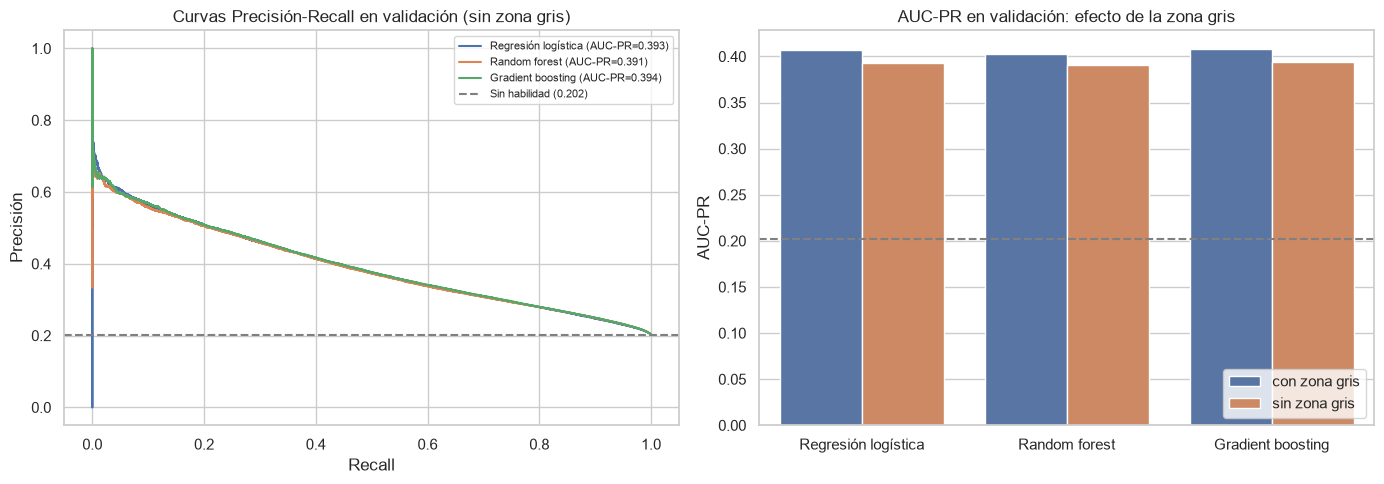

In [12]:
modelos = list(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curvas Precisión-Recall (sin zona gris) + línea del azar
colores = dict(zip(modelos, sns.color_palette("deep", 3)))
for name in modelos:
    key = (name, "sin zona gris")
    pr, rc, _ = precision_recall_curve(y_va, scores[key])
    axes[0].plot(rc, pr, label=f"{name} (AUC-PR={resultados[key]['pr_auc']:.3f})", color=colores[name])
axes[0].axhline(y_va.mean(), color="gray", ls="--", label=f"Sin habilidad ({y_va.mean():.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precisión")
axes[0].set_title("Curvas Precisión-Recall en validación (sin zona gris)")
axes[0].legend(loc="upper right", fontsize=8)

# AUC-PR con y sin zona gris
plot_df = tabla.reset_index()
plot_df = plot_df[plot_df["modelo"].isin(modelos)]
sns.barplot(data=plot_df, x="modelo", y="pr_auc", hue="variante", order=modelos, ax=axes[1])
axes[1].axhline(y_va.mean(), color="gray", ls="--")
axes[1].set_title("AUC-PR en validación: efecto de la zona gris")
axes[1].set_xlabel(""); axes[1].set_ylabel("AUC-PR"); axes[1].legend(loc="lower right")
plt.tight_layout()
savefig("03_comparacion_modelos")
plt.show()


In [13]:
efecto = tabla.reset_index()
efecto = efecto[efecto["modelo"].isin(modelos)].pivot(index="modelo", columns="variante", values=["pr_auc", "ks"])
efecto[("pr_auc", "ganancia zona gris")] = efecto[("pr_auc", "con zona gris")] - efecto[("pr_auc", "sin zona gris")]
efecto[("ks", "ganancia zona gris")] = efecto[("ks", "con zona gris")] - efecto[("ks", "sin zona gris")]
efecto.round(4)


pr_auc                          ks                \
variante            con zona gris sin zona gris con zona gris sin zona gris   
modelo                                                                        
Gradient boosting          0.4078        0.3941        0.3365        0.3102   
Random forest              0.4030        0.3908        0.3342        0.3037   
Regresión logística        0.4071        0.3931        0.3365        0.3075   

                                pr_auc                 ks  
variante            ganancia zona gris ganancia zona gris  
modelo                                                     
Gradient boosting               0.0136             0.0263  
Random forest                   0.0122             0.0304  
Regresión logística             0.0139             0.0290

**Lectura de la zona gris:** (completar) cuánto suben AUC-PR y KS al agregar `grade`/`sub_grade`/`int_rate`.
Si la mejora es grande, el modelo con zona gris está en buena parte replicando el scoring de Lending Club, y la variante «sin zona gris» es la que mide mejor el riesgo con información propia de la solicitud.


## 6. Calibración

Para riesgo crediticio importa que la probabilidad sea creíble, no solo que ordene bien. Los modelos con `class_weight` inflan las probabilidades de la clase minoritaria,
así que se espera que logística y random forest estén descalibrados; esto no afecta el ranking (AUC-PR, KS) pero sí cualquier lectura directa de la probabilidad.


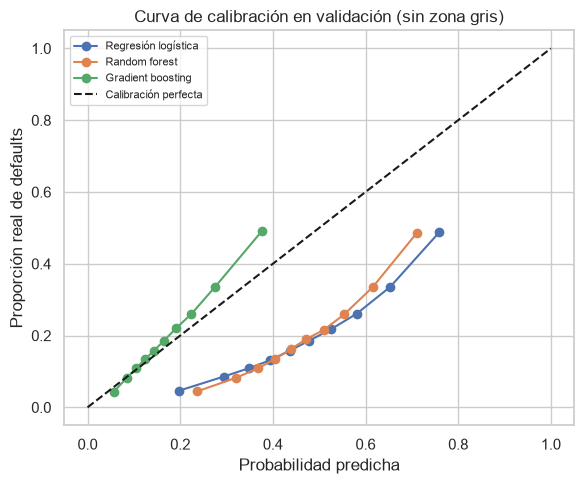

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in modelos:
    frac_pos, mean_pred = calibration_curve(y_va, scores[(name, "sin zona gris")], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name, color=colores[name])
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Proporción real de defaults")
ax.set_title("Curva de calibración en validación (sin zona gris)")
ax.legend(fontsize=8)
plt.tight_layout()
savefig("03_calibracion")
plt.show()


## 7. Selección del modelo y estabilidad temporal

El modelo principal es la familia con mayor AUC-PR en validación **entre las variantes sin zona gris**. La variante con zona gris se reporta como análisis aparte.


Modelo principal (mayor AUC-PR en valid, sin zona gris): Gradient boosting


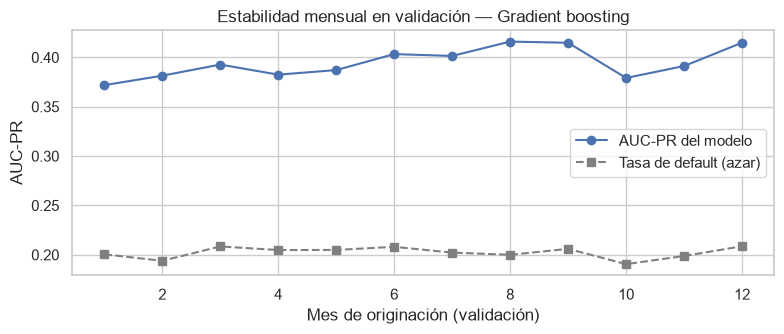

In [15]:
sin_gris = tabla.reset_index()
sin_gris = sin_gris[(sin_gris["variante"] == "sin zona gris") & (sin_gris["modelo"].isin(modelos))]
primary = sin_gris.sort_values("pr_auc", ascending=False).iloc[0]["modelo"]
print("Modelo principal (mayor AUC-PR en valid, sin zona gris):", primary)

# Estabilidad dentro de 2015: AUC-PR por mes de originación
p_best = scores[(primary, "sin zona gris")]
mensual = []
for mes, idx in valid.reset_index(drop=True).groupby(valid["issue_date"].dt.month.values).groups.items():
    idx = np.asarray(list(idx))
    if len(np.unique(y_va[idx])) == 2:
        mensual.append({"mes": mes, "pr_auc": evaluate.evaluate_scores(y_va[idx], p_best[idx])["pr_auc"],
                        "tasa_default": y_va[idx].mean()})
mensual = pd.DataFrame(mensual)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mensual["mes"], mensual["pr_auc"], marker="o", label="AUC-PR del modelo")
ax.plot(mensual["mes"], mensual["tasa_default"], marker="s", ls="--", color="gray", label="Tasa de default (azar)")
ax.set_xlabel("Mes de originación (validación)"); ax.set_ylabel("AUC-PR")
ax.set_title(f"Estabilidad mensual en validación — {primary}")
ax.legend()
plt.tight_layout()
savefig("03_estabilidad_mensual")
plt.show()


**Lectura:** (completar) si el AUC-PR del modelo se mantiene por encima del azar todos los meses, el desempeño es estable dentro del período de validación; caídas marcadas serían una señal temprana de *drift*.


## 8. Guardar resultados

In [16]:
tabla.round(6).to_csv(config.OUTPUTS / "model_comparison_valid.csv")


def _json_default(o):
    return o.item() if hasattr(o, "item") else str(o)


payload = {
    "seed": SEED,
    "split": {"train_years": list(config.TRAIN_YEARS), "valid_year": config.VALID_YEAR, "test_year": config.TEST_YEAR,
              "only_term": config.ONLY_TERM},
    "primary_model": primary,
    "include_grey_zone": False,
    "best_params": best_params,
    "valid_metrics": {f"{m} | {v}": vals for (m, v), vals in resultados.items()},
    "search": {"sample_rows": len(search_df), "n_temporal_folds": len(folds), "quick_run": QUICK},
    "note": "Hiperparámetros elegidos con CV temporal dentro de train; el test NO se usó en este notebook.",
}
with open(config.OUTPUTS / "best_params.json", "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2, ensure_ascii=False, default=_json_default)
print("Guardado en", config.OUTPUTS)


Guardado en C:\Users\JOSSEMY-PC\ProyectosVSC\proyecto-ML\outputs


## 9. Conclusiones 

**1. Desempeño del baseline:** El modelo sin habilidad obtuvo un AUC-PR de 0.2019, correspondiente a la tasa de incumplimiento en validación. Por su parte, la regresión logística inicial alcanzó un AUC-PR de 0.3928 y un KS de 0.3074. Estos resultados muestran que las variables seleccionadas contienen información útil para distinguir entre préstamos pagados e incumplidos.

**2. Comparación de los tres modelos:** Se compararon regresión logística, Random Forest y Gradient Boosting mediante validación temporal y búsqueda de hiperparámetros. Sin utilizar variables de zona gris, Gradient Boosting obtuvo el mejor AUC-PR (0.3941), seguido de regresión logística (0.3931) y Random Forest (0.3908).
Sin embargo, las diferencias fueron pequeñas. La ventaja de Gradient Boosting sobre la regresión logística fue de solo 0.0010 puntos de AUC-PR. Por lo tanto, no existe evidencia suficiente para afirmar que los modelos más complejos presentan una mejora importante.

**3. Búsqueda de hiperparámetros:** La validación cruzada temporal obtuvo AUC-PR promedio de 0.3030 para regresión logística, 0.3014 para Random Forest y 0.3006 para Gradient Boosting. Las diferencias entre configuraciones fueron considerablemente menores que la variabilidad entre los folds. Esto indica que el ajuste de hiperparámetros no produjo mejoras sustanciales y que conviene evitar configuraciones excesivamente complejas.

**4. Efecto de las variables de zona gris:** Al incorporar `grade`, `sub_grade` e `int_rate`, todos los modelos mejoraron, Gradient Boosting aumentó su AUC-PR de 0.3941 a 0.4078 y su KS de 0.3102 a 0.3365, esto indica que las calificaciones crediticias de Lending Club contienen información predictiva adicional. Sin embargo, también significa que parte de la mejora proviene de incorporar la evaluación de riesgo realizada previamente por la plataforma.
Por esta razón, se mantiene como principal la versión sin zona gris.

**5. Calibración y estabilidad temporal:** Gradient Boosting obtuvo el mejor Brier Score entre los modelos evaluados sin zona gris (0.1466), frente a 0.2177 de regresión logística y 0.2143 de Random Forest, las curvas muestran que regresión logística y Random Forest tienden a sobreestimar las probabilidades de incumplimiento en varios rangos. Gradient Boosting presenta una calibración más favorable en términos generales, aunque también muestra desviaciones en las probabilidades altas.
En el análisis mensual de 2015, Gradient Boosting mantuvo un AUC-PR aproximadamente entre 0.37 y 0.42, superando la referencia sin habilidad durante todos los meses evaluados.

**6. Selección del modelo final:** Se seleccionó **Gradient Boosting sin zona gris** como modelo principal, debido a que obtuvo el mayor AUC-PR en validación (0.3941), un KS de 0.3102 y un recall de 0.4418 al exigir una precisión mínima de 0.40.No obstante, la regresión logística sigue siendo una alternativa competitiva por su mayor interpretabilidad y su rendimiento muy similar.
Como siguiente paso, corresponde evaluar el modelo seleccionado una sola vez sobre el conjunto de test de 2016, considerando las limitaciones de censura identificadas durante la limpieza.
